In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns
pd.set_option("display.max_columns", None)

# Set visualization style
sns.set_theme(style="whitegrid")

print("GeoPulse EDA Environment Ready!")

GeoPulse EDA Environment Ready!


In [2]:
from pathlib import Path

project_root = Path.cwd().parent

dataset_path = (
    project_root / "data" / "raw" / "gps_pings.csv"
)

df = pd.read_csv(dataset_path)

# Convert Timestamp into datetime format
df["Timestamp"] = pd.to_datetime(df["Timestamp"])

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (10000, 6)


,DeviceID,Lat,Long,Timestamp,Zone,Activity
0,DEV0001,19.119925,72.847082,2026-11-16 07:00:00,Andheri,Home
1,DEV0001,19.118065,72.876009,2026-11-16 08:00:00,In_Transit,Commuting
2,DEV0001,19.117638,72.905905,2026-11-16 09:00:00,Powai,Work
3,DEV0001,19.117595,72.905744,2026-11-16 12:30:00,Powai,Work
4,DEV0001,19.117864,72.906233,2026-11-16 14:00:00,Powai,Work


In [3]:
# Extract date and hour from Timestamp

df["Date"] = df["Timestamp"].dt.date
df["Hour"] = df["Timestamp"].dt.hour

print("New columns added successfully!")

df[["Timestamp", "Date", "Hour"]].head(10)


New columns added successfully!


,Timestamp,Date,Hour
0,2026-11-16 07:00:00,2026-11-16,7
1,2026-11-16 08:00:00,2026-11-16,8
2,2026-11-16 09:00:00,2026-11-16,9
3,2026-11-16 12:30:00,2026-11-16,12
4,2026-11-16 14:00:00,2026-11-16,14
5,2026-11-16 17:30:00,2026-11-16,17
6,2026-11-16 18:00:00,2026-11-16,18
7,2026-11-16 19:00:00,2026-11-16,19
8,2026-11-16 20:00:00,2026-11-16,20
9,2026-11-16 21:00:00,2026-11-16,21


ANALYZE GPS RECORDS BY HOURS


In [4]:
hourly_activity = df.groupby("Hour").size()

print(hourly_activity)

Hour
7     1000
8     1000
9     1000
12    1000
14    1000
17    1000
18    1000
19    1000
20    1000
21    1000
dtype: int64


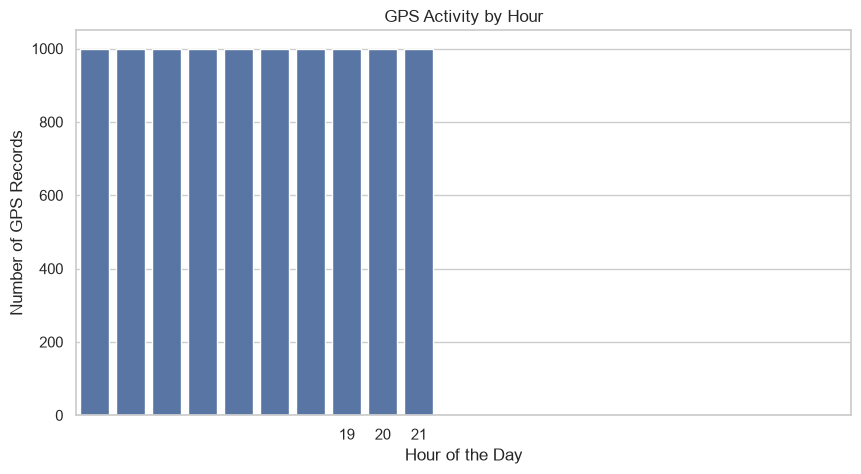

In [5]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=hourly_activity.index,
    y=hourly_activity.values
)

plt.title("GPS Activity by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Number of GPS Records")
plt.xticks(range(7, 22))
plt.show()